# Car Acceptability Prediction (Simple ML)

**Goal:** Predict how acceptable a car is (`unacc`, `acc`, `good`, `vgood`) from six attributes.

**Dataset:** UCI Car Evaluation, 1,728 cars, no missing values (Bohanec, 1988).

| Feature | Meaning | Levels (low to high) |
|---|---|---|
| `buying` | buying price | low, med, high, vhigh |
| `maint` | maintenance cost | low, med, high, vhigh |
| `doors` | number of doors | 2, 3, 4, 5more |
| `persons` | passenger capacity | 2, 4, more |
| `lug_boot` | luggage boot size | small, med, big |
| `safety` | estimated safety | low, med, high |

**Models (5 in total, all simple):**
1. Majority-class baseline (reference only)
2. Logistic Regression
3. Decision Tree (best model)
4. K-Nearest Neighbors (k=5)
5. Naive Bayes

**Outputs:** figures are saved to `figures/`, and result tables are saved to `results/`.

In [12]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import OrdinalEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

os.makedirs('figures', exist_ok=True)
os.makedirs('results', exist_ok=True)

def save_fig(name):
    plt.savefig(f'figures/{name}.png', dpi=150, bbox_inches='tight')

plt.rcParams['figure.dpi'] = 100
print('Libraries loaded')

Libraries loaded


## 1. Load the data

The raw file `car.data` has no header row, so we add the column names (from `car.names`).

In [13]:
columns = ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class']
df = pd.read_csv('data/car.data', header=None, names=columns)
print('Shape (rows, columns):', df.shape)
print('Missing values:', int(df.isna().sum().sum()))
print('Duplicate rows:', int(df.duplicated().sum()))
df.head()

Shape (rows, columns): (1728, 7)
Missing values: 0
Duplicate rows: 0


,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


## 2. Check the target

About 70% of cars are `unacc`, so the classes are **imbalanced**. Accuracy alone can be misleading, so we also use **macro F1**, which gives each class equal weight.

class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64


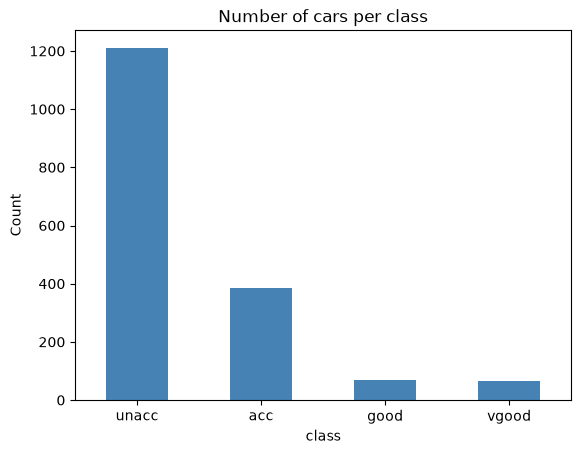

In [14]:
class_order = ['unacc', 'acc', 'good', 'vgood']
counts = df['class'].value_counts().reindex(class_order)
print(counts)

counts.plot(kind='bar', color='steelblue', title='Number of cars per class')
plt.ylabel('Count'); plt.xticks(rotation=0)
save_fig('01_class_distribution')
plt.show()

## 3. Encode the features as numbers

The levels have a natural order (`low < med < high`), so we use **ordinal encoding**: low = 0, med = 1, and so on.

In [15]:
categories = [
    ['low', 'med', 'high', 'vhigh'],   # buying
    ['low', 'med', 'high', 'vhigh'],   # maint
    ['2', '3', '4', '5more'],          # doors
    ['2', '4', 'more'],                # persons
    ['small', 'med', 'big'],           # lug_boot
    ['low', 'med', 'high'],            # safety
]
features = ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety']

encoder = OrdinalEncoder(categories=categories)
X = pd.DataFrame(encoder.fit_transform(df[features]), columns=features).astype(int)
y = df['class'].map({c: i for i, c in enumerate(class_order)})

print('Encoded features (first rows):')
X.head()

Encoded features (first rows):


,buying,maint,doors,persons,lug_boot,safety
0,3,3,0,0,0,0
1,3,3,0,0,0,1
2,3,3,0,0,0,2
3,3,3,0,0,1,0
4,3,3,0,0,1,1


## 4. Train / test split

80% of the cars train the models and 20% test them. `stratify=y` keeps the class proportions the same in both sets.

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print('Training cars:', len(X_train))
print('Test cars    :', len(X_test))

Training cars: 1382
Test cars    : 346


## 5. Build the 5 models

The decision tree depth is chosen with 5-fold cross-validation on the **training** set. We search only depths 2 to 6 so that the tree stays small enough to read.

In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
depth_scores = {}
for d in range(2, 7):
    tree = DecisionTreeClassifier(max_depth=d, random_state=42)
    depth_scores[d] = cross_val_score(tree, X_train, y_train, cv=cv, scoring='f1_macro').mean()

best_depth = max(depth_scores, key=depth_scores.get)
print('CV macro F1 by depth:', {d: round(s, 3) for d, s in depth_scores.items()})
print('Chosen depth:', best_depth)

models = {
    'Majority baseline': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(max_depth=best_depth, random_state=42),
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5),
    'Naive Bayes': CategoricalNB(min_categories=[4, 4, 4, 3, 3, 3]),
}

CV macro F1 by depth: {2: np.float64(0.391), 3: np.float64(0.361), 4: np.float64(0.551), 5: np.float64(0.614), 6: np.float64(0.81)}
Chosen depth: 6


## 6. Train and test every model

In [18]:
rows = []
fitted = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    fitted[name] = model
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision (macro)': precision_score(y_test, pred, average='macro', zero_division=0),
        'Recall (macro)': recall_score(y_test, pred, average='macro', zero_division=0),
        'F1 (macro)': f1_score(y_test, pred, average='macro', zero_division=0),
    })

results = pd.DataFrame(rows).set_index('Model').round(4).sort_values('F1 (macro)', ascending=False)
results

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Model,,,,
Decision Tree,0.9393,0.8121,0.8701,0.8379
KNN (k=5),0.9133,0.9250,0.7604,0.8131
Logistic Regression,0.8006,0.6693,0.5570,0.5980
Naive Bayes,0.8410,0.6714,0.5098,0.5415
Majority baseline,0.6994,0.1749,0.2500,0.2058


## 7. Compare the models

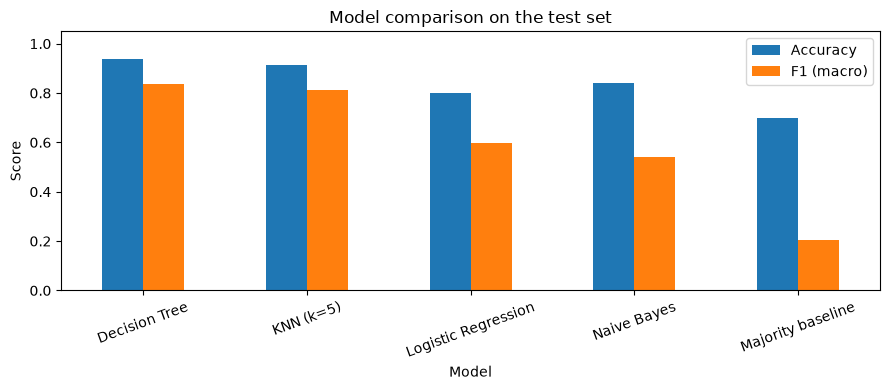

Saved results/model_comparison.csv


In [19]:
ax = results[['Accuracy', 'F1 (macro)']].plot(kind='bar', figsize=(9, 4), rot=20,
                                             title='Model comparison on the test set')
ax.set_ylim(0, 1.05); ax.set_ylabel('Score')
plt.tight_layout()
save_fig('02_model_comparison')
plt.show()

results.to_csv('results/model_comparison.csv')
print('Saved results/model_comparison.csv')

## 8. Best model: confusion matrix and per-class report

Rows are the true class and columns are the predicted class. The report shows precision and recall for each class separately, so you can see how the rare classes are handled.

Best model by macro F1: Decision Tree


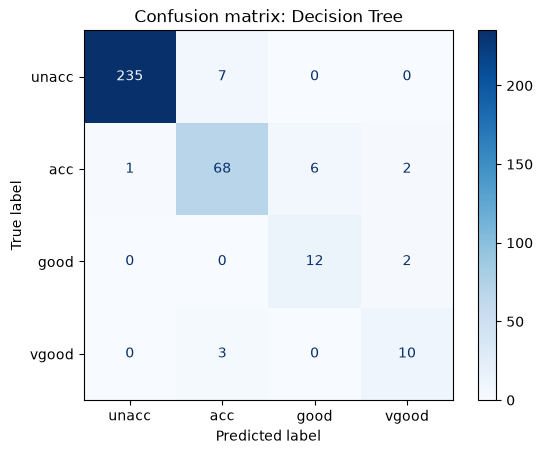

              precision    recall  f1-score   support

       unacc       1.00      0.97      0.98       242
         acc       0.87      0.88      0.88        77
        good       0.67      0.86      0.75        14
       vgood       0.71      0.77      0.74        13

    accuracy                           0.94       346
   macro avg       0.81      0.87      0.84       346
weighted avg       0.94      0.94      0.94       346



In [20]:
best_name = results.index[0]
print('Best model by macro F1:', best_name)
pred_best = fitted[best_name].predict(X_test)

ConfusionMatrixDisplay(confusion_matrix(y_test, pred_best), display_labels=class_order).plot(cmap='Blues')
plt.title(f'Confusion matrix: {best_name}')
save_fig('03_confusion_matrix')
plt.show()

print(classification_report(y_test, pred_best, target_names=class_order, zero_division=0))

## 9. Which features matter? (Decision Tree)

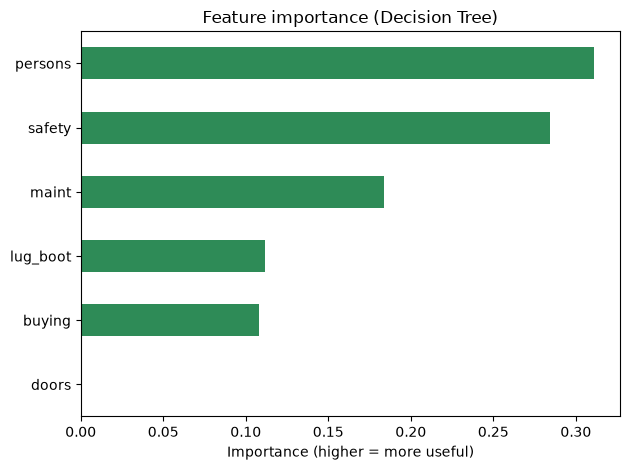

persons     0.311
safety      0.284
maint       0.184
lug_boot    0.112
buying      0.108
doors       0.001
dtype: float64

In [21]:
dt = fitted['Decision Tree']
importance = pd.Series(dt.feature_importances_, index=features).sort_values()

importance.plot(kind='barh', color='seagreen', title='Feature importance (Decision Tree)')
plt.xlabel('Importance (higher = more useful)')
plt.tight_layout()
save_fig('04_feature_importance')
plt.show()

importance.sort_values(ascending=False).round(3).to_csv('results/feature_importance.csv', header=['importance'])
importance.sort_values(ascending=False).round(3)

## 10. Prediction on a new car

Give the features of a car and the model returns its predicted acceptability.

In [22]:
def predict_car(buying, maint, doors, persons, lug_boot, safety, model=dt):
    row = pd.DataFrame([[buying, maint, doors, persons, lug_boot, safety]], columns=features)
    row_enc = pd.DataFrame(encoder.transform(row), columns=features).astype(int)
    return class_order[model.predict(row_enc)[0]]

print('Example 1 (cheap, 4 seats, big boot, high safety):',
      predict_car('low', 'low', '4', '4', 'big', 'high'))
print('Example 2 (very expensive, 2 seats, low safety):  ',
      predict_car('vhigh', 'vhigh', '2', '2', 'small', 'low'))
print('Example 3 (medium everything):                    ',
      predict_car('med', 'med', '4', '4', 'med', 'med'))

Example 1 (cheap, 4 seats, big boot, high safety): vgood
Example 2 (very expensive, 2 seats, low safety):   unacc
Example 3 (medium everything):                     good


## 11. Conclusion

- The **Decision Tree** performs best on the test set (about **94% accuracy**, **0.84 macro F1**). KNN is close behind.
- **Number of persons** and **safety** are the most important features. A car with low safety or only 2 seats is always `unacc`.
- **Maintenance cost** and **luggage boot size** come next. **Number of doors** has almost no effect.
- **Logistic Regression** draws straight-line boundaries, but the acceptability rules depend on combinations of features, so it does poorly.
- **Naive Bayes** assumes the features are independent, which they are not here, so it misses the rare `good` and `vgood` classes.
- The majority baseline gets about 70% accuracy by always guessing `unacc`, but it never finds a good car.

The Decision Tree is the easiest model to explain: its decisions can be read as simple rules.